In [ ]:
from IPython.display import display
from IPython.utils.capture import capture_output
from bert_score import BERTScorer
from collections import Counter
from huggingface_hub import snapshot_download
from io import BytesIO
from json import JSONDecodeError
from nltk.corpus import wordnet
from nltk.tokenize import wordpunct_tokenize
from nltk.translate.meteor_score import meteor_score
from pathlib import Path
from rank_bm25 import BM25Okapi
from rouge_score import rouge_scorer
from time import perf_counter
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
import base64
import datasets
import json
import math
import matplotlib
import matplotlib.pyplot as plt
import nltk
import pandas as pd
import pickle
import re
import torch

In [2]:
def save_intermediate(filename, content):
    with open(f"intermediate_states/{filename}.json", "w", encoding="utf-8") as file:
        file.write(json.dumps(content))

def load_intermediate(filename):
    with open(f"intermediate_states/{filename}.json", "r", encoding="utf-8") as file:
        return json.loads(file.read())

Path("intermediate_states").mkdir(parents=True, exist_ok=True)

In [ ]:
MODEL_CACHE_DIR = Path(".cache")
MODEL_CACHE_DIR.mkdir(parents=True, exist_ok=True)

def create_agent(name):
    tokenizer = AutoTokenizer.from_pretrained(name, cache_dir=MODEL_CACHE_DIR)
    model = AutoModelForCausalLM.from_pretrained(
        name,
        torch_dtype="auto",
        device_map="auto",
        cache_dir=MODEL_CACHE_DIR,
    )
    agent = {
        "name": name,
        "model": model,
        "tokenizer": tokenizer,
    }
    return agent

agent1 = create_agent("Qwen/Qwen3-0.6B") # information extraction
agent2 = create_agent("HuggingFaceTB/SmolLM2-1.7B-Instruct") # drafting
agent3 = create_agent("LiquidAI/LFM2.5-1.2B-Instruct") # verification
agent4 = create_agent("ibm-granite/granite-3.3-2b-instruct") # revision

In [ ]:
def prompt_messages(agent, messages):
    tokenizer = agent["tokenizer"]
    model = agent["model"]

    if agent["name"] == "Qwen/Qwen3-0.6B":
        kwargs = {"enable_thinking": False}
    else:
        kwargs = {}
    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_tensors="pt",
        **kwargs,
    )
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    inputs_end = inputs["input_ids"].shape[1]

    ids = model.generate(
        **inputs,
        max_new_tokens=4096,
        do_sample=True,
        temperature=0.6,
        top_p=0.95,
        top_k=20,
        min_p=0.0,
    )
    ids = ids[0][inputs_end:].tolist()

    content = tokenizer.decode(ids, skip_special_tokens=True).strip()
    return content

def prompt(agent, system, user):
    messages = []
    messages.append({"role": "system", "content": system})
    messages.append({"role": "user",   "content": user})
    return prompt_messages(agent, messages)

Step 1: Dataset Extraction, Filtering & Clinical Schema Mapping

In [ ]:
# Download and filter the dataset, calculate some statistics
def step1():
    def normalize(word):
        word = word.lower()
        word = "".join([c for c in word if c.isalpha()])
        return word

    def get_avg_word_count(notes):
        word_count = [len(note.split()) for note in notes]
        return sum(word_count) / len(word_count)

    def get_avg_len(notes):
        lengths = [len(note) for note in notes]
        return sum(lengths) / len(lengths)

    def get_vocab_size(notes):
        vocab = set()
        for note in notes:
            for word in note.split():
                word = normalize(word)
                vocab.add(word)
        return len(vocab)

    dataset_name = "starmpcc/Asclepius-Synthetic-Clinical-Notes"
    splits = datasets.load_dataset(dataset_name)
    df = splits["train"] # The dataset doesn't have a validation/test set
    df = df.to_pandas()

    # filtering
    df = df[df["task"] == "Summarization"]
    df = df.dropna()
    df = df.drop_duplicates()
    for column in df.columns:
        df = df[df[column] != ""] # drop every row with empty strings

    # sampling
    sample = df.sample(100, random_state=67)

    # calculate statistics
    avg_word_count = get_avg_word_count(df["note"])
    avg_len = get_avg_len(df["note"])
    vocab_size = get_vocab_size(df["note"])

    return df, sample, avg_word_count, avg_len, vocab_size

dataset, sample, avg_word_count, avg_len, vocab_size = step1()
notes = sample["note"]

print(f"Average note word count: {avg_word_count:.2f}")
print(f"Average note length:     {avg_len:.2f}")
print(f"Note vocabulary size:    {vocab_size}")

Step 2: Build the Information Extraction Agent (Agent 1)

In [ ]:
# Extract the relevant information from the notes into a list of jsons
def step2(notes, agent):
    system_prompt = (
        'You will be given a clinical note in the first user message.\n'
        'You will need to extract relevant information from the clinical note.\n'
        'Relevant information includes primary diagnoses, secondary conditions, critical lab abnormalities, procedures performed, discharge medications and follow up instructions.\n'
        'The output needs to be a valid JSON.\n'
        'If a field has no relevant information, return an empty list [] or an empty string "".\n'
        'Do not give anything other than the valid JSON as output.\n'
        'Do not wrap the JSON in markdown code fences or add any explanation.\n'
        'The output needs to be in following format:\n'
        '{\n'
        '  "primary_diagnoses": [string, ...],\n'
        '  "secondary_conditions": [string, ...],\n'
        '  "critical_lab_abnormalities": [string, ...],\n'
        '  "procedures_performed": [string, ...],\n'
        '  "medications_discharge": [string, ...],\n'
        '  "follow_up_instructions": string\n'
        '}\n'
        'Only include information supported by the note.\n'
        'Do not infer or invent.'
    )

    responses = []
    for i, note in enumerate(notes, 1):
        print(f"{i}/{len(notes)}")
        while True:
            # Prompt on the same note as long as the response is an invalid json
            response = prompt(agent, system_prompt, note)
            try:
                response = json.loads(response)
                break
            except JSONDecodeError:
                continue
        responses.append(response)

    return responses

In [ ]:
patient_details = step2(notes, agent1) # Run the actual code...
save_intermediate("step2", patient_details) # ...and save the result

In [ ]:
patient_details = load_intermediate("step2") # Skip step 2 by loading the saved result

Step 3: Implement Single-Agent Baseline

In [ ]:
# Summarize each note into an organized clinical summary similarly to step 2
def step3(notes, agent):
    system_prompt = (
        'You will be given a clinical note in the first user message.\n'
        'You will need to summarize the clinical note using 200-350 words.\n'
        'Write the summary for a clinician, in clinical terminology.\n'
        'You may include relevant information such as reason for encounter, key findings, active problems and plan/follow-up.\n'
        'Do not give anything other than the summary as output.\n'
        'Do not use any markdown in the output or add any explanation.\n'
        'Only include information supported by the note.\n'
        'Do not infer or invent.'
    )

    responses = []
    for i, note in enumerate(notes, 1):
        print(f"{i}/{len(notes)}")
        response = prompt(agent, system_prompt, note)
        responses.append(response)

    return responses

In [ ]:
summaries = step3(notes, agent1)
save_intermediate("step3", summaries)

In [ ]:
summaries = load_intermediate("step3")

Step 4: Construct Global Evidence Retrieval Index

In [ ]:
STEP4_CHUNK_SIZE = 300
STEP4_CHUNK_OVERLAP = 50
STEP4_TOKENIZER_NAME = agent1["name"]
STEP4_TOKENIZER = agent1["tokenizer"]
STEP4_CHUNK_NOTES_PATH = Path("intermediate_states/step4_chuck_notes.json") # chunk notes storage path
STEP4_INDEX_PATH = Path("intermediate_states/step4_chuck_index.pkl") # BM25 index storage path
STEP4_CHUNKS_BY_NOTE = {}
STEP4_BM25_INDEX = None

# Converts text to lowercase and extracts word-like terms for BM25.
def tokenize_for_bm25(text):
    return re.findall(r"[a-z0-9]+(?:['-][a-z0-9]+)*", text.lower())

# Divide each clinical note into text chunks of 250–350 tokens with a 50-token overlap between adjacent chunks
def chunk_notes(sample, chunk_size=STEP4_CHUNK_SIZE, overlap=STEP4_CHUNK_OVERLAP):
    if not 250 <= chunk_size <= 350:
        raise ValueError("The project brief requires chunks between 250 and 350 tokens.")
    if not 0 <= overlap < chunk_size:
        raise ValueError("overlap must be non-negative and smaller than chunk_size.")

    stride = chunk_size - overlap
    chunks = []
    for row_index, row in sample.iterrows():
        base_id = row.get("source_id", row.get("patient_id", "sample"))
        source_id = f"{base_id}-row-{row_index}"
        note_text = row["note"]
        if not isinstance(note_text, str) or not note_text.strip():
            raise ValueError(f"Note {source_id} must be a non-empty string.")

        token_ids = STEP4_TOKENIZER.encode(note_text, add_special_tokens=False)
        for chunk_number, token_start in enumerate(range(0, len(token_ids), stride)):
            token_end = min(token_start + chunk_size, len(token_ids))
            chunk_text = STEP4_TOKENIZER.decode(token_ids[token_start:token_end], skip_special_tokens=True).strip()
            if chunk_text:
                chunks.append({
                    "source_id": str(source_id),
                    "chunk_id": f"{source_id}-chunk-{chunk_number:03d}",
                    "token_start": token_start,
                    "token_end": token_end,
                    "token_count": token_end - token_start,
                    "tokenizer": STEP4_TOKENIZER_NAME,
                    "text": chunk_text,
                })
            if token_end == len(token_ids):
                break

    save_intermediate("step4_chuck_notes", chunks)
    return chunks

# Index these chunks locally using BM25 (rank-bm25)
def build_note_indexes():
    if STEP4_CHUNK_NOTES_PATH.exists():
        chunk_records = load_intermediate("step4_chuck_notes")
    else:
        chunk_records = []

    if not chunk_records:
        if "sample" not in globals():
            raise RuntimeError(
                "step4_chuck_notes.json is missing or empty; run Step 1 to regenerate the chunks."
            )
        chunk_records = chunk_notes(sample)

    chunks_by_note = {}
    for chunk in chunk_records:
        source_id = str(chunk["source_id"])
        chunks_by_note.setdefault(source_id, []).append(chunk)

    for note_chunks in chunks_by_note.values():
        note_chunks.sort(key=lambda chunk: chunk["token_start"])

    all_chunks = [
        chunk
        for source_id in sorted(chunks_by_note)
        for chunk in chunks_by_note[source_id]
    ]
    tokenized_corpus = [tokenize_for_bm25(chunk["text"]) for chunk in all_chunks]
    if not tokenized_corpus or any(not tokens for tokens in tokenized_corpus):
        raise ValueError("The global chunk corpus must contain searchable tokens.")

    global_index = BM25Okapi(tokenized_corpus)
    index_record = {
        "index_type": "global_bm25_pickle",
        "tokenizer": STEP4_TOKENIZER_NAME,
        "global_index": global_index,
        "chunks": all_chunks,
    }
    with STEP4_INDEX_PATH.open("wb") as index_file:
        pickle.dump(index_record, index_file, protocol=pickle.HIGHEST_PROTOCOL)
    return chunks_by_note, global_index, all_chunks


STEP4_CHUNKS_BY_NOTE, STEP4_BM25_INDEX, step4_all_chunks = build_note_indexes()

print("Indexed notes:", len(STEP4_CHUNKS_BY_NOTE))
print("Total chunks:", len(step4_all_chunks))
print("Saved chunk notes:", STEP4_CHUNK_NOTES_PATH)
print("Saved serialized global BM25 index:", STEP4_INDEX_PATH)

In [ ]:
# a helper function: given a statement from a summary, search the source note
# and return the top_k most relevant text chunks
def retrieve_evidence(statement, top_k=2):
    if top_k < 1:
        raise ValueError("top_k must be at least 1.")
    if not STEP4_INDEX_PATH.exists():
        raise FileNotFoundError(f"Build the Step 4 index first: {STEP4_INDEX_PATH}")
    query_terms = tokenize_for_bm25(statement)
    if not query_terms:
        raise ValueError("statement must contain at least one searchable token.")

    with STEP4_INDEX_PATH.open("rb") as index_file:
        index_record = pickle.load(index_file)
    if index_record.get("index_type") != "global_bm25_pickle":
        raise ValueError("The saved Step 4 file does not contain a serialized global BM25 index.")

    global_index = index_record["global_index"]
    scores = global_index.get_scores(query_terms)
    chunks = index_record["chunks"]
    ranked_indices = sorted(range(len(scores)), key=lambda index: (-scores[index], index))[:top_k]
    return [
        {**chunks[index], "bm25_score": float(scores[index])}
        for index in ranked_indices
    ]

# Update sample statement to retrieve top_k most relevant chunks
sample_statement = 'The patient was treated with high dose aspirin, IVIG, and infliximab as per the hospital protocol. Follow-up appointments with Cardiology and PCP were scheduled'
sample_results = retrieve_evidence(sample_statement, top_k=2)

print("Global search returned", len(sample_results), "chunks from",
      sorted({result["source_id"] for result in sample_results}))

for rank, result in enumerate(sample_results, start=1):
    print(f"\nRelevant chunk {rank}:", result["source_id"])
    print("BM25 score:", f"{result['bm25_score']:.4f}")
    print(result["text"])

Step 5: Assemble Multi-Agent Workflow (Generation, Verification & Revision)

In [ ]:
# Write an initial clinical summary based on the information extracted by the first agent
def step5_draft_summary(patient_details, agent):
    def flatten(details):
        primary_diagnoses          = ", ".join(details["primary_diagnoses"]) if "primary_diagnoses" in details else ""
        secondary_conditions       = ", ".join(details["secondary_conditions"]) if "secondary_conditions" in details else ""
        critical_lab_abnormalities = ", ".join(details["critical_lab_abnormalities"]) if "critical_lab_abnormalities" in details else ""
        procedures_performed       = ", ".join(details["procedures_performed"]) if "procedures_performed" in details else ""
        medications_discharge      = ", ".join(details["medications_discharge"]) if "medications_discharge" in details else ""
        follow_up_instructions     = details["follow_up_instructions"] if "follow_up_instructions" in details else ""
        return (
            '{\n'
            f'  "primary_diagnoses": [{primary_diagnoses}],\n'
            f'  "secondary_conditions": [{secondary_conditions}],\n'
            f'  "critical_lab_abnormalities": [{critical_lab_abnormalities}],\n'
            f'  "procedures_performed": [{procedures_performed}],\n'
            f'  "medications_discharge": [{medications_discharge}],\n'
            f'  "follow_up_instructions": {follow_up_instructions}\n'
            '}'
        )

    system_prompt = (
        'You will be given key patient details extracted from a clinical note in the first user message.\n'
        'You will need to write an initial clinical summary based on the key patient details using 200-350 words.\n'
        'The input will be in the following format:\n'
        '{\n'
        '  "primary_diagnoses": [string, ...],\n'
        '  "secondary_conditions": [string, ...],\n'
        '  "critical_lab_abnormalities": [string, ...],\n'
        '  "procedures_performed": [string, ...],\n'
        '  "medications_discharge": [string, ...],\n'
        '  "follow_up_instructions": string\n'
        '}\n'
        'Write the summary for a clinician, in clinical terminology.\n'
        'You may include relevant information such as reason for encounter, key findings, active problems and plan/follow-up.\n'
        'Do not give anything other than the summary as output.\n'
        'Do not use any markdown in the output or add any explanation.\n'
        'Only include information supported by the patient details.\n'
        'Do not infer or invent.'
    )

    responses = []
    for i, details in enumerate(patient_details, 1):
        print(f"{i}/{len(patient_details)}")
        response = prompt(agent, system_prompt, flatten(details))
        responses.append(response)

    return responses

In [ ]:
# Write factual statements based on the summary, expand abbreviations and categorize each statement using the source note
def step5_draft_statement(summaries, notes, agent):
    def expand(statements):
        lines = statements.split("\n")
        lines = [[dictionary[word.lower()] if word.lower() in dictionary else word for word in line.split()] for line in lines]
        lines = "\n".join([" ".join(line) for line in lines])
        return lines

    def get_dictionary():
        with open("dictionary.txt", "r", encoding="utf-8") as file:
            dictionary = file.read()
        dictionary = dictionary.strip().split("\n")
        dictionary = [(dictionary[i], dictionary[i+1]) for i in range(0, len(dictionary), 2)]
        dictionary = [(k.lower(), v) for k, v in dictionary]
        for k, v in dictionary:
            if "." in k:
                dictionary.append((k.replace(".", ""), v))
        dictionary = dict(dictionary)
        return dictionary

    system_prompt = (
        'You will be given some instructions in each user message.\n'
        'Your job is to follow the instructions and only return what the instructions tell you to return.\n'
        'Do not give anything other than what the instructions ask for as output.\n'
        'Do not use any markdown in the output or add any explanation.\n'
        'Only include information supported by the input.\n'
        'Do not infer or invent.'
    )

    prompt1 = (
        'You will be given a draft summary of a clinical note in the next user message.\n'
        'You will need to break the draft summary into individual factual statements.\n'
        'The output will need to be in the following format:\n'
        '1. [STATEMENT]\n'
        '2. [STATEMENT]\n'
        '3. [STATEMENT]\n'
        '...\n'
        'Where each [STATEMENT] is an individual factual statement.\n'
        'Write the statements for a clinician, in clinical terminology.\n'
        'Do not give anything other than the statements as output.\n'
        'Do not use any markdown in the output or add any explanation.\n'
        'Only include information supported by the summary.\n'
        'Do not infer or invent.'
    )

    prompt2 = (
        'You will be given the source note from which the draft summary was built in the next user message.\n'
        'You will need to categorize each statement into one of the following categories:\n'
        'Supported, Unsupported, Contradictory or Omitted Critical Finding.\n'
        'The output will need to be in the following format:\n'
        '1. [CATEGORY] [STATEMENT]\n'
        '2. [CATEGORY] [STATEMENT]\n'
        '3. [CATEGORY] [STATEMENT]\n'
        '...\n'
        'Where each [STATEMENT] is an individual factual statement you extracted previously and [CATEGORY] is one of the four categories surrounded by square brackets.\n'
        'You need to base the categorization on evidence gathered from the source note.\n'
        'Do not give anything other than the categories and the statements as output.\n'
        'Do not use any markdown in the output or add any explanation.\n'
        'Do not infer or invent.'
    )

    dictionary = get_dictionary()
    responses = []
    for i, (summary, note) in enumerate(zip(summaries, notes), 1):
        print(f"{i}/{len(summaries)}")
        messages = []
        messages.append({"role": "system",    "content": system_prompt})
        messages.append({"role": "user",      "content": prompt1})
        messages.append({"role": "user",      "content": summary})
        response = prompt_messages(agent, messages)
        response = expand(response)

        messages.append({"role": "assistant", "content": response})
        messages.append({"role": "user",      "content": prompt2})
        messages.append({"role": "user",      "content": note})
        response = prompt_messages(agent, messages)

        responses.append(response)

    return responses

In [ ]:
# Verifying each statement using the draft summaries gathered previously. Remove or modify incorrect statements.
def step5_revision(summaries, statements, agent):
    system_prompt = (
        'You will be given a summary of a clinical note in the first user message and a list of factual statements in the second user message.\n'
        'You will need to revise the summary by rewriting or removing unsupported claims according to the list of factual statements.\n'
        'Each factual statement has already been categorized into one of the following categories:\n'
        'Supported, Unsupported, Contradictory or Omitted Critical Finding.\n'
        'The factual statements will be in the following format:\n'
        '1. [CATEGORY] [STATEMENT]\n'
        '2. [CATEGORY] [STATEMENT]\n'
        '3. [CATEGORY] [STATEMENT]\n'
        '...\n'
        'Where each [STATEMENT] is an individual statement and [CATEGORY] is one of the four categories surrounded by square brackets.\n'
        'Do not give anything other than the revised summary as output.\n'
        'Do not use any markdown in the output or add any explanation.\n'
        'Do not infer or invent.'
    )

    responses = []
    for i, (summary, statement) in enumerate(zip(summaries, statements), 1):
        print(f"{i}/{len(summaries)}")
        messages = []
        messages.append({"role": "system", "content": system_prompt})
        messages.append({"role": "user",   "content": summary})
        messages.append({"role": "user",   "content": statement})
        response = prompt_messages(agent, messages)
        responses.append(response)

    return responses

Step 6: Pipeline Execution & Intermediate State TracingStep

In [ ]:
draft_summaries = step5_draft_summary(patient_details, agent2)
save_intermediate("step5_draft_summaries", draft_summaries)

draft_statements = step5_draft_statement(draft_summaries, notes, agent3)
save_intermediate("step5_draft_statements", draft_statements)

revised_summaries = step5_revision(draft_summaries, draft_statements, agent4)
save_intermediate("step5_revised_summaries", revised_summaries)

In [ ]:
draft_summaries = load_intermediate("step5_draft_summaries")
draft_statements = load_intermediate("step5_draft_statements")
revised_summaries = load_intermediate("step5_revised_summaries")

In [ ]:
logs = []
for i, (summary, draft_summary, statement, revised_summary) in enumerate(zip(summaries, draft_summaries, draft_statements, revised_summaries), 1):
    row = {
        "id": i,
        "summary": {
            "baseline": summary,
            "draft": draft_summary,
            "revised": revised_summary,
        },
        "statements": statement,
    }
    logs.append(row)

save_intermediate("step6_result", logs)
print(logs)

Step 7: Automated Evaluation (ROUGE, BERTScore, METEOR)

In [ ]:
### 7.1 Prepare aligned evaluation inputs
def step7_prepare_inputs(sample, summaries, draft_summaries, revised_summaries, expected_cases=100):
    if not {"note", "answer"}.issubset(sample.columns):
        raise ValueError("The Step 1 sample must contain note and answer columns.")
    if len(sample) != expected_cases or not sample.index.is_unique:
        raise ValueError(f"Expected {expected_cases} cases with unique dataset indices.")
    variants = {
        "baseline": summaries,
        "draft": draft_summaries,
        "revised": revised_summaries,
    }
    texts = {"note": sample["note"].tolist(), "answer": sample["answer"].tolist(), **variants}
    for label, values in texts.items():
        if not isinstance(values, (list, tuple)) or len(values) != expected_cases:
            raise ValueError(f"{label} must contain exactly {expected_cases} texts.")
        for position, text in enumerate(values, 1):
            if not isinstance(text, str) or not text.strip():
                raise ValueError(f"{label}, case {position}: expected a non-empty string.")
    rows = []
    for position, (dataset_index, case) in enumerate(sample.iterrows()):
        for variant, predictions in variants.items():
            rows.append({
                "case_id": position + 1,
                "dataset_index": str(dataset_index),
                "variant": variant,
                "note": case["note"],
                "reference": case["answer"],
                "prediction": predictions[position],
            })
    return pd.DataFrame(rows)

In [ ]:
### 7.2 Calculate automatic metrics
def step7_calculate_rouge(evaluation_inputs):
    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)
    rows = []
    for case in evaluation_inputs.itertuples(index=False):
        scores = scorer.score(case.reference, case.prediction)
        rows.append({name: score.fmeasure for name, score in scores.items()})
    return pd.DataFrame(rows, index=evaluation_inputs.index)

def step7_calculate_meteor(evaluation_inputs, cache_dir=Path(".cache")):
    nltk_dir = str((Path(cache_dir) / "nltk").resolve())
    Path(nltk_dir).mkdir(parents=True, exist_ok=True)
    if nltk_dir not in nltk.data.path:
        nltk.data.path.insert(0, nltk_dir)
    try:
        wordnet.ensure_loaded()
    except LookupError:
        nltk.download("wordnet", download_dir=nltk_dir, raise_on_error=True)
        wordnet.ensure_loaded()
    scores = [
        meteor_score(
            [wordpunct_tokenize(case.reference.lower())],
            wordpunct_tokenize(case.prediction.lower()),
        )
        for case in evaluation_inputs.itertuples(index=False)
    ]
    return pd.DataFrame({"meteor": scores}, index=evaluation_inputs.index)

def step7_calculate_bertscore(evaluation_inputs, cache_dir=Path(".cache"), batch_size=8):
    if batch_size < 1:
        raise ValueError("BERTScore batch_size must be at least 1.")
    model_path = snapshot_download(
        "distilbert/distilbert-base-uncased",
        cache_dir=str(cache_dir),
        allow_patterns=["*.json", "*.txt", "*.safetensors"],
    )
    scorer = BERTScorer(
        model_type=model_path,
        num_layers=6,
        batch_size=batch_size,
        device="cpu",
        idf=False,
        rescale_with_baseline=False,
        use_fast_tokenizer=True,
    )
    _, _, f1 = scorer.score(
        evaluation_inputs["prediction"].tolist(),
        evaluation_inputs["reference"].tolist(),
        batch_size=batch_size,
    )
    return pd.DataFrame({"bertscore_f1": f1.cpu().tolist()}, index=evaluation_inputs.index)

def step7_calculate_scores(evaluation_inputs):
    scores = pd.concat([
        evaluation_inputs[["case_id", "dataset_index", "variant"]],
        step7_calculate_rouge(evaluation_inputs),
        step7_calculate_meteor(evaluation_inputs),
        step7_calculate_bertscore(evaluation_inputs),
    ], axis=1)
    if scores[["rouge1", "rouge2", "rougeL", "meteor", "bertscore_f1"]].isna().any().any():
        raise ValueError("Evaluation produced missing scores.")
    return scores

def step7_save_results(per_case):
    aggregate = per_case.groupby("variant", sort=False).agg(
        case_count=("case_id", "size"),
        **{column: (column, "mean") for column in per_case.columns
           if column not in ("case_id", "dataset_index", "variant")},
    ).reset_index()
    save_intermediate("step7_per_case", per_case.to_dict(orient="records"))
    save_intermediate("step7_aggregate", aggregate.to_dict(orient="records"))

summaries = load_intermediate("step3")
draft_summaries = load_intermediate("step5_draft_summaries")
revised_summaries = load_intermediate("step5_revised_summaries")
step7_inputs = step7_prepare_inputs(sample, summaries, draft_summaries, revised_summaries)
with capture_output():
    step7_metric_scores = step7_calculate_scores(step7_inputs)
step7_save_results(step7_metric_scores)
save_intermediate("step7_settings", {
    "reference_column": "answer", "rouge": "F1, stemming enabled",
    "meteor_tokenizer": "lowercase wordpunct_tokenize",
    "bertscore_model": "distilbert/distilbert-base-uncased", "bertscore_num_layers": 6,
    "bertscore_idf": False, "bertscore_rescale_with_baseline": False,
    "compression_ratio": "summary_words / source_words",
    "alignment": "Positional; summaries must use the Step 1 sample order.",
})
step7_metric_means = step7_metric_scores.groupby("variant", sort=False)[[
    "rouge1", "rouge2", "rougeL", "meteor", "bertscore_f1",
]].mean().reset_index()
step7_metric_means["variant"] = step7_metric_means["variant"].map({
    "baseline": "Single-Agent Baseline",
    "draft": "Initial Draft (before revision)",
    "revised": "Final Revised Summary",
})
display(step7_metric_means.rename(columns={
    "variant": "Summary", "rouge1": "ROUGE-1", "rouge2": "ROUGE-2",
    "rougeL": "ROUGE-L", "meteor": "METEOR", "bertscore_f1": "BERTScore (F1)",
}))

In [ ]:
### 7.3 Measure summary length and compression
def step7_calculate_lengths(evaluation_inputs):
    lengths = pd.DataFrame(index=evaluation_inputs.index)
    lengths["summary_words"] = evaluation_inputs["prediction"].str.split().str.len()
    lengths["reference_words"] = evaluation_inputs["reference"].str.split().str.len()
    lengths["source_words"] = evaluation_inputs["note"].str.split().str.len()
    lengths["compression_ratio"] = lengths["summary_words"] / lengths["source_words"]
    lengths["summary_reference_ratio"] = lengths["summary_words"] / lengths["reference_words"]
    return lengths

def step7_compare_revision_lengths(per_case):
    word_counts = per_case.pivot(index="case_id", columns="variant", values="summary_words")
    comparison = word_counts.rename(columns={
        "baseline": "baseline_words", "draft": "draft_words", "revised": "revised_words",
    }).reset_index()
    comparison.columns.name = None
    comparison["revised_minus_draft_words"] = comparison["revised_words"] - comparison["draft_words"]
    comparison["revised_draft_word_ratio"] = comparison["revised_words"] / comparison["draft_words"]
    comparison["revision_is_longer"] = comparison["revised_words"] > comparison["draft_words"]
    return comparison

step7_length_inputs = step7_prepare_inputs(sample, summaries, draft_summaries, revised_summaries)
if not step7_length_inputs.equals(step7_inputs):
    raise ValueError("Step 7 inputs changed. Rerun 7.2 before saving length results in 7.3.")
step7_lengths = pd.concat([
    step7_length_inputs[["case_id", "dataset_index", "variant"]],
    step7_calculate_lengths(step7_length_inputs),
], axis=1)
step7_length_means = step7_lengths.groupby("variant", sort=False)[[
    "summary_words", "reference_words", "source_words",
    "compression_ratio", "summary_reference_ratio",
]].mean().reset_index()
step7_length_means["variant"] = step7_length_means["variant"].map({
    "baseline": "Single-Agent Baseline",
    "draft": "Initial Draft (before revision)",
    "revised": "Final Revised Summary",
})
display(step7_length_means.rename(columns={
    "variant": "Summary", "summary_words": "Mean summary words",
    "reference_words": "Mean reference words", "source_words": "Mean source words",
    "compression_ratio": "Mean compression ratio (summary/source)",
    "summary_reference_ratio": "Mean summary/reference word ratio",
}))
step7_revision_lengths = step7_compare_revision_lengths(step7_lengths)
step7_per_case = step7_metric_scores.merge(
    step7_lengths, on=["case_id", "dataset_index", "variant"], validate="one_to_one",
)
step7_save_results(step7_per_case)
save_intermediate("step7_revision_lengths", step7_revision_lengths.to_dict(orient="records"))
display(pd.DataFrame([{
    "Mean revised-minus-draft words": step7_revision_lengths["revised_minus_draft_words"].mean(),
    "Mean revised/draft word ratio": step7_revision_lengths["revised_draft_word_ratio"].mean(),
    "Fraction of revisions longer than drafts": step7_revision_lengths["revision_is_longer"].mean(),
}]))

In the current run, revised summaries average **92.57 words**, compared with **60.34 words** for initial drafts and **148.68 words** for the baseline. Their mean summary-to-source compression ratio is **0.353**, and **90%** of revisions are longer than their drafts.

Although revised summaries remain shorter than the baseline, they are substantially longer than the initial drafts. These statistics therefore **cannot confirm that score improvements are independent of added length** or rule out length-related score inflation.

Step 8: Manual Verification & Factuality Audit

In [ ]:
### 8.1 Display cases 1-15 for review
def step8_display_cases(sample, draft_summaries, draft_statements, revised_summaries):
    if not {"note", "answer"}.issubset(sample.columns) or not sample.index.is_unique:
        raise ValueError("Use the Step 1 sample with unique dataset indices and note and answer columns.")
    outputs = {
        "Original source note": sample["note"].tolist(),
        "Original answer (reference summary)": sample["answer"].tolist(),
        "Initial draft": draft_summaries,
        "Verification log": draft_statements,
        "Revised summary": revised_summaries,
    }
    for label, values in outputs.items():
        if not isinstance(values, (list, tuple)):
            raise ValueError(f"{label} must be a list or tuple of texts.")
        if len(values) != len(draft_summaries):
            raise ValueError("Source notes, answers, drafts, verification logs, and revised summaries must have equal lengths.")
        if any(not isinstance(text, str) or not text.strip() for text in values):
            raise ValueError(f"{label} contains an empty or invalid text.")
    if len(draft_summaries) < 15:
        raise ValueError("At least 15 aligned cases are required for the Step 8 review.")
    selected_positions = range(15)
    for review_id, position in enumerate(selected_positions, 1):
        print(f"Review {review_id} - Case {position + 1}")
        print("=" * 80)
        for label, values in outputs.items():
            print(f"\n{label}:\n{values[position]}")
        print("\n" + "-" * 80 + "\n")
    return [position + 1 for position in selected_positions]

# Lists must retain the same case order as the saved Step 5 outputs.
# Always review the first 15 cases in Step 1 sample order; returned IDs are 1-based.
step8_case_ids = step8_display_cases(sample, draft_summaries, draft_statements, revised_summaries)

### 8.2 Overall observations: verification accuracy and revision quality

These observations are based on **cases 1-15 in the Step 1 sample order**, comparing the original notes with the drafts, verification logs, and revised summaries. The original note is used to check whether each detail is correct. Since only the first 15 cases are included, the findings do not necessarily apply to the whole dataset.

#### Verification accuracy

**Did the verification agent correctly catch real errors, or falsely flag correct statements?**

The verification agent corrects some errors and adds missing details. For example, cases 2 and 13 have the correct ages and sex in the verification logs: a 26-year-old female and a 17-year-old female. In case 3, the log includes small cell lung cancer and the patient's death about six months after chemotherapy. In case 12, it adds the right lung and pancreatic lesions. However, the agent usually rewrites the information rather than clearly marking which draft statements are wrong.

There is no clear example in these logs of a correct statement being explicitly flagged as incorrect. This does not mean that there are no false positives. Most logs do not label individual statements, and the labels in case 15 are separated from the statements they are supposed to describe. Because of this, the logs are not clear enough to calculate a reliable false-positive rate, precision, or recall.

**Did any hallucinations slip past the verifier undetected?**

Yes. Incorrect or unsupported ages or sex remain in the revised summaries of **9 cases: 1, 2, 5, 6, 8, 9, 10, 12, and 15**. This includes both errors missed during verification and corrections that the revision agent did not use. For example, case 1 describes a female patient without a stated age as a 65-year-old male. Case 12 changes age 19 to 45, and case 15 changes age 54 to 25. Case 10 adds age 32 and female sex even though these are not stated in the note, which also mentions reduced nocturnal erections. In case 2, the verifier gives the correct age and sex, but the revised summary still describes a 55-year-old male.

Other errors also pass through the workflow. Case 1 includes jaundice even though the note describes anicteric cholestasis. Case 4 presents radiotherapy as ongoing although it had already finished. Case 13 says weekly arch-wire changes continued for 10 years and 10 months, but this period actually refers to follow-up. In case 14, the draft and revision claim normal laboratory results, no procedures, no discharge medication, and specific follow-up instructions when these details are not provided. Information missing from a note should not be treated as proof that a finding or treatment was absent.

The verifier sometimes adds unsupported details itself. In case 5, it places the m.3243A>G mutation in the transplanted kidney, while the note describes a leucocyte heteroplasmy measurement without establishing that location. In case 11, it says all CSF tau, ptau, and A-beta measurements were elevated, although the note only says they were abnormal. In case 15, it describes a bevacizumab taper instead of the documented prednisone taper and two bevacizumab injections. These errors appear again in the revised summaries. In case 7, the verifier adds PCR confirmation of leishmaniasis even though the PCR result concerns the CML response; this particular error is not kept in the revision.

#### Revision quality

**Did revision fix flagged errors or introduce new mistakes?**

The revision agent fixes some problems, but leaves others unchanged and introduces new mistakes. Since the verification logs do not clearly label each error, an exact correction rate cannot be calculated. The main observations are:

- **Errors fixed and useful details added:** Case 13 corrects age 14 to 17. Case 2 no longer lists hearing loss as a laboratory abnormality and adds the stable imaging follow-up. Case 3 includes small cell lung cancer and the fatal outcome, and no longer lists chemotherapy as a discharge medication. Case 9 presents the culture result as an observed result rather than a follow-up instruction and adds the T2 A. castellani genotype. Case 15 includes improvement after the second injection and correctly describes the 24-month follow-up as an observed outcome rather than a future appointment.
- **Errors and omissions that remain:** The age or sex problems in the nine cases listed above are not corrected. Case 4 keeps the wrong radiotherapy timing, case 13 keeps the incorrect weekly-treatment duration, and case 14 keeps unsupported negative findings and follow-up advice. Case 12 still leaves out the lung and pancreatic lesions even though they appear in the verification log. Case 6 describes the patient as currently critical despite the improved condition at discharge.
- **Verification errors repeated in the revision:** Cases 5, 11, and 15 repeat the unsupported mutation location, elevated CSF measurements, and bevacizumab taper described above. Case 10 also repeats the verifier's confusion between tests for autoimmune or inflammatory conditions and germ-cell tumor markers.
- **New mistakes introduced during revision:** In case 7, the verifier correctly states that imatinib was stopped after six months because of pancytopenia, but the revision names hydroxyurea instead. In case 8, the revision says chemotherapy and a Behcet's diagnosis are not provided, although the note and verification log include R-CHOP and Behcet's disease. Case 5 also changes past peritoneal dialysis into current dialysis without support from the note.

**Overall conclusion:** In these 15 cases, verification and revision recover some important missing information, but they do not consistently remove factual errors. Some incorrect details survive both stages, some are added by the verifier, and others appear during revision. The results therefore show mixed revision quality rather than a consistent improvement in accuracy. Clear statement-level labels would make verification easier to evaluate. Longer summaries or higher similarity scores alone are not enough to show that a summary is more factually correct.


Step 9: Component Comparison (Ablation Test) and Resource Measurement

### 9.1 Run an ablation test

Compare the full pipeline (Extraction -> Drafting -> Verification -> Revision) with the same pipeline without extraction (raw note -> Drafting -> Verification -> Revision) on **cases 1-20 in Step 1 sample order**. Both versions use the same downstream models, generation settings, and summary instructions, except for the drafting input format. Verification receives the original note in both versions.

The first 20 notes are selected before generation. The full pipeline reuses Step 2 extraction and Step 5 drafting, verification, and revision. The version without extraction uses a raw-note drafting helper, followed by the same Step 5 verification and revision functions.

Verification is timed separately per case, covering both statement splitting and factual checking, with GPU synchronization at timer boundaries. The numbered statement list actually submitted for checking is captured without changing Step 5. Both variants retain these measurements in the Step 9 results. Full-pipeline measurements are also checkpointed to `intermediate_states/step10_verification_usage.json` for Step 10.5.

In [ ]:
def step9_sync_devices():
    if torch.cuda.is_available():
        for device in range(torch.cuda.device_count()):
            torch.cuda.synchronize(device)

def step9_verify(draft, note, agent):
    submitted = []
    class VerificationTokenizer:
        def __getattr__(self, name):
            return getattr(agent["tokenizer"], name)

        def apply_chat_template(self, messages, **kwargs):
            statements = [message["content"] for message in messages if message["role"] == "assistant"]
            if statements:
                if len(statements) != 1:
                    raise ValueError("Expected one statement list in the verification checking prompt.")
                submitted.append(statements[0])
            return agent["tokenizer"].apply_chat_template(messages, **kwargs)

    measured_agent = {**agent, "tokenizer": VerificationTokenizer()}
    step9_sync_devices()
    started = perf_counter()
    verification = step5_draft_statement([draft], [note], measured_agent)[0]
    step9_sync_devices()
    seconds = perf_counter() - started
    if len(submitted) != 1 or not isinstance(submitted[0], str):
        raise ValueError("Could not capture the statement list submitted for verification.")
    statements = submitted[0].strip()
    items = list(re.finditer(r"(?m)^\s*(\d+)\.\s+(\S[^\n]*)", statements))
    if (not items or statements[:items[0].start()].strip()
            or [int(item.group(1)) for item in items] != list(range(1, len(items) + 1))):
        raise ValueError("Verification statements must be a numbered list starting at 1; inspect the splitter output before plotting.")
    return verification, {
        "verification_seconds": seconds, "statements_checked": len(items),
        "submitted_statements": statements,
    }

def step9_measure_agents(agents, calls):
    class MeasuredModel:
        def __init__(self, model, stage):
            self.model = model
            self.stage = stage

        def __getattr__(self, name):
            return getattr(self.model, name)

        def generate(self, **kwargs):
            input_ids = kwargs["input_ids"]
            if input_ids.shape[0] != 1:
                raise ValueError("Step 9 measurement expects one document per model call.")
            output = self.model.generate(**kwargs)
            input_tokens = input_ids.shape[1]
            output_tokens = output.shape[1] - input_tokens
            calls.append({
                "stage": self.stage, "input_tokens": input_tokens,
                "output_tokens": output_tokens, "total_tokens": input_tokens + output_tokens,
            })
            return output

    return {stage: {**agent, "model": MeasuredModel(agent["model"], stage)}
            for stage, agent in agents.items()}

def step9_draft_raw_note(note, agent):
    system_prompt = (
        'You will be given a clinical note in the first user message.\n'
        'You will need to write an initial clinical summary based on the clinical note using 200-350 words.\n'
        'Write the summary for a clinician, in clinical terminology.\n'
        'You may include relevant information such as reason for encounter, key findings, active problems and plan/follow-up.\n'
        'Do not give anything other than the summary as output.\n'
        'Do not use any markdown in the output or add any explanation.\n'
        'Only include information supported by the clinical note.\n'
        'Do not infer or invent.'
    )
    return prompt(agent, system_prompt, note)

def step9_run_ablation(sample, extraction_agent, drafting_agent, verification_agent, revision_agent):
    if not {"note", "answer"}.issubset(sample.columns) or not sample.index.is_unique:
        raise ValueError("Use the Step 1 sample with unique indices and note and answer columns.")
    if len(sample) < 20:
        raise ValueError("The ablation test requires at least 20 notes.")
    ablation_sample = sample.iloc[:20].copy()
    ablation_notes = ablation_sample["note"].tolist()
    for column in ("note", "answer"):
        if any(not isinstance(text, str) or not text.strip() for text in ablation_sample[column]):
            raise ValueError(f"The first 20 cases contain an empty or invalid {column}.")

    results = {
        "case_ids": list(range(1, 21)),
        "models": {
            "extraction": extraction_agent["name"],
            "drafting": drafting_agent["name"],
            "verification": verification_agent["name"],
            "revision": revision_agent["name"],
        },
        "complete": False,
        "data_origin": "measured",
        "records": [],
    }
    usage = {"data_origin": results["data_origin"], "models": results["models"], "complete": False, "documents": []}
    verification_usage = {"measurement_type": "measured", "variant": "full", "complete": False, "records": []}
    save_intermediate("step9_ablation", results)
    save_intermediate("step9_compute_usage", usage)
    save_intermediate("step10_verification_usage", verification_usage)
    for position, (dataset_index, row) in enumerate(ablation_sample.iterrows()):
        note = ablation_notes[position]
        case_id = position + 1
        seeds = {stage: 67 + position * 4 + offset for offset, stage in enumerate(
            ("extraction", "drafting", "verification", "revision")
        )}
        variants = ("full", "without_extraction") if position % 2 == 0 else ("without_extraction", "full")
        for variant in variants:
            print(f"Case {case_id}/20 - {variant}")
            calls = []
            measured = step9_measure_agents({
                "extraction": extraction_agent, "drafting": drafting_agent,
                "verification": verification_agent, "revision": revision_agent,
            }, calls)
            step9_sync_devices()
            started = perf_counter()
            details = None
            if variant == "full":
                set_seed(seeds["extraction"])
                details = step2([note], measured["extraction"])[0]
                if not isinstance(details, dict):
                    raise ValueError(f"Case {case_id}: extraction must return a JSON object.")
            set_seed(seeds["drafting"])
            # draft summary agent
            if variant == "full":
                draft = step5_draft_summary([details], measured["drafting"])[0]
            else:
                draft = step9_draft_raw_note(note, measured["drafting"])
            if not isinstance(draft, str) or not draft.strip():
                raise ValueError(f"Case {case_id} ({variant}): drafting returned empty or invalid text.")
            set_seed(seeds["verification"])
            # verification agent
            verification, verification_measurement = step9_verify(draft, note, measured["verification"])
            if not isinstance(verification, str) or not verification.strip():
                raise ValueError(f"Case {case_id} ({variant}): verification returned empty or invalid text.")
            set_seed(seeds["revision"])
            # revision agent
            revised = step5_revision([draft], [verification], measured["revision"])[0]
            if not isinstance(revised, str) or not revised.strip():
                raise ValueError(f"Case {case_id} ({variant}): revision returned empty or invalid text.")
            step9_sync_devices()
            runtime_seconds = perf_counter() - started
            measurement = {
                **verification_measurement,
                "case_id": case_id, "variant": variant,
                "input_tokens": sum(call["input_tokens"] for call in calls),
                "output_tokens": sum(call["output_tokens"] for call in calls),
                "total_tokens": sum(call["total_tokens"] for call in calls),
                "runtime_seconds": runtime_seconds, "calls": calls,
            }
            usage["documents"].append(measurement)
            results["records"].append({
                **measurement,
                "case_id": case_id,
                "dataset_index": str(dataset_index),
                "variant": variant,
                "source_note": row["note"],
                "reference_answer": row["answer"],
                "seeds": seeds.copy(),
                "extracted_details": details,
                "draft_summary": draft,
                "verification_log": verification,
                "revised_summary": revised,
            })
            save_intermediate("step9_ablation", results)
            save_intermediate("step9_compute_usage", usage)
            if variant == "full":
                verification_usage["records"].append({"case_id": case_id, **verification_measurement})
                save_intermediate("step10_verification_usage", verification_usage)
    results["complete"] = True
    usage["complete"] = True
    verification_usage["complete"] = True
    save_intermediate("step10_verification_usage", verification_usage)
    save_intermediate("step9_ablation", results)
    save_intermediate("step9_compute_usage", usage)
    return results

def step9_load_ablation():
    results = load_intermediate("step9_ablation")
    if not isinstance(results, dict) or results.get("complete") is not True:
        raise ValueError("The saved ablation run is incomplete. Finish Step 9.1 before using its results.")
    records = results.get("records")
    expected_pairs = {(case_id, variant) for case_id in range(1, 21) for variant in ("full", "without_extraction")}
    if not isinstance(records, list) or len(records) != 40 or any(not isinstance(record, dict) for record in records):
        raise ValueError("Expected 40 saved ablation records: two versions for each of 20 cases.")
    pairs = [(record.get("case_id"), record.get("variant")) for record in records]
    if any(pair not in expected_pairs for pair in pairs) or len(set(pairs)) != 40:
        raise ValueError("Saved ablation results must contain both versions for cases 1-20 without duplicates.")
    return results

In [ ]:
step9_ablation = step9_run_ablation(sample, agent1, agent2, agent3, agent4)

### 9.2 Compute usage per document

In [ ]:
step9_compute_usage = load_intermediate("step9_compute_usage")
step9_usage_table = pd.DataFrame(step9_compute_usage["documents"])[
    ["case_id", "variant", "input_tokens", "output_tokens", "total_tokens", "runtime_seconds"]
].sort_values(["case_id", "variant"]).reset_index(drop=True)

with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(step9_usage_table)

### 9.3 Factual accuracy versus compute cost

The full pipeline uses **78,000 tokens** across 20 notes, compared with **79,997 tokens** without extraction. Including extraction would therefore save **1,997 tokens**, or about **2.5%** compared with the version without extraction. Its average runtime would be **36.41 seconds per document**, compared with **36.98 seconds**, saving **0.57 seconds per document**, or about **1.6%**. The difference is quite small in terms of the tokens used and the running time, so there is not much reason to choose one or the other with regards to these metrics.

The difference between the pipelines could be mostly explained by the architecture of the models. They are supposed to produce unique output on each invocation, which makes measuring some ground truth characteristics much less trivial. If we would like to extract results that more closely match the mean, we would need to scale up our test by increasing the amount of samples used by multiple magnitudes. It should be stated, however, that we have only measured the amount of time and tokens used, but not the accuracy of the output. This would need to be measured seperately in order to pick the better pipeline out of the two.

Step 10: Results Visualization (Charts & Figures)

### 10.1 Pipeline Diagram: A clean diagram showing the flow of data between agents.

![Clinical summarization pipeline](pipeline-diagram.svg)

### 10.2 Compare evaluation scores

Mean ROUGE-1, ROUGE-2, ROUGE-L, and BERTScore F1 for the Single-Agent Baseline, Initial Draft, and Final Revised Summary, loaded from `intermediate_states/step7_aggregate.json`. These metrics measure reference similarity, not factual accuracy.

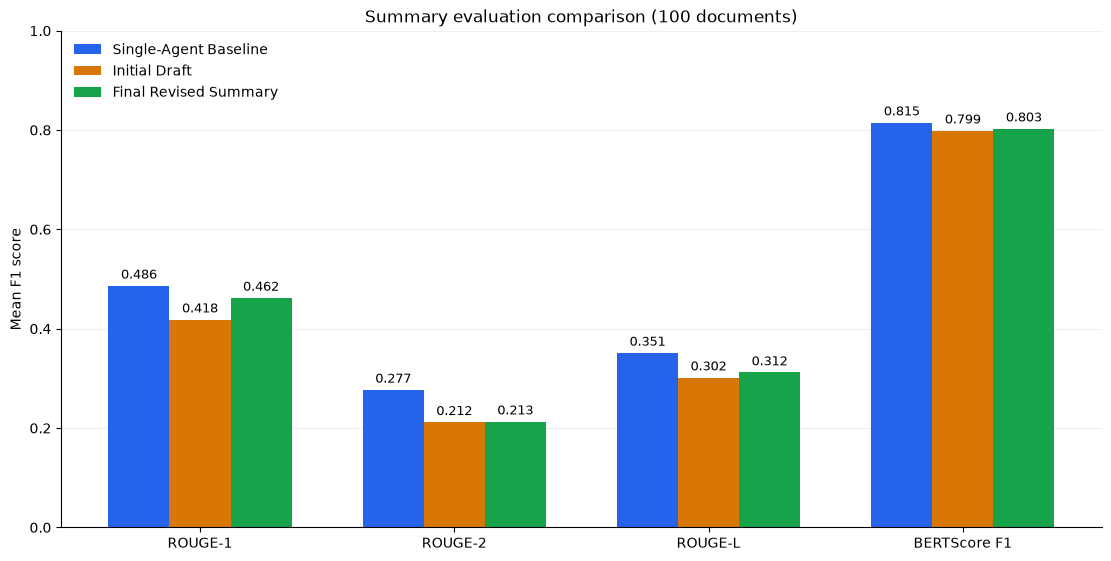

In [3]:
def step10_plot_metric_comparison(aggregate):
    variants = ["baseline", "draft", "revised"]
    metrics = ["rouge1", "rouge2", "rougeL", "bertscore_f1"]
    labels = ["Single-Agent Baseline", "Initial Draft", "Final Revised Summary"]
    scores = pd.DataFrame(aggregate)
    if not {"variant", "case_count", *metrics}.issubset(scores.columns):
        raise ValueError("Step 7 aggregate scores are missing required fields. Rerun Step 7.")
    if len(scores) != 3 or set(scores["variant"]) != set(variants):
        raise ValueError("Expected one aggregate record for each of baseline, draft, and revised.")
    scores = scores.set_index("variant").loc[variants]
    values = scores[metrics].apply(pd.to_numeric, errors="raise")
    if values.isna().any().any() or not values.ge(0).all().all() or not values.le(1).all().all():
        raise ValueError("Expected finite evaluation scores between zero and one.")
    counts = pd.to_numeric(scores["case_count"], errors="raise")
    if counts.isna().any() or counts.nunique() != 1 or (counts <= 0).any() or (counts % 1 != 0).any():
        raise ValueError("All three variants must cover the same positive number of cases.")
    fig, ax = plt.subplots(figsize=(11, 5.5), layout="constrained")
    colors = ["#2563eb", "#d97706", "#16a34a"]
    width = 0.24
    for index, (variant, label, color) in enumerate(zip(variants, labels, colors)):
        positions = [metric + (index - 1) * width for metric in range(len(metrics))]
        bars = ax.bar(positions, values.loc[variant], width=width, label=label, color=color)
        ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.set_xticks(range(len(metrics)), ["ROUGE-1", "ROUGE-2", "ROUGE-L", "BERTScore F1"])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Mean F1 score")
    ax.set_title(f"Summary evaluation comparison ({int(counts.iloc[0])} documents)")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", frameon=False)
    return fig, ax

step10_metric_figure, step10_metric_axes = step10_plot_metric_comparison(
    load_intermediate("step7_aggregate")
)
plt.show()

### 10.3 Verification flags by error type

Count every non-supported bracketed category label in both `statements` and `summary.revised` for all 100 cases in `intermediate_states/step6_result.json`, including inline and detached labels. Spacing and capitalization differences are accepted. Each occurrence is counted, including repeated labels across the two fields. Unbracketed labels are excluded. These are label occurrences, not unique or independently confirmed errors; unlabeled errors are not represented.

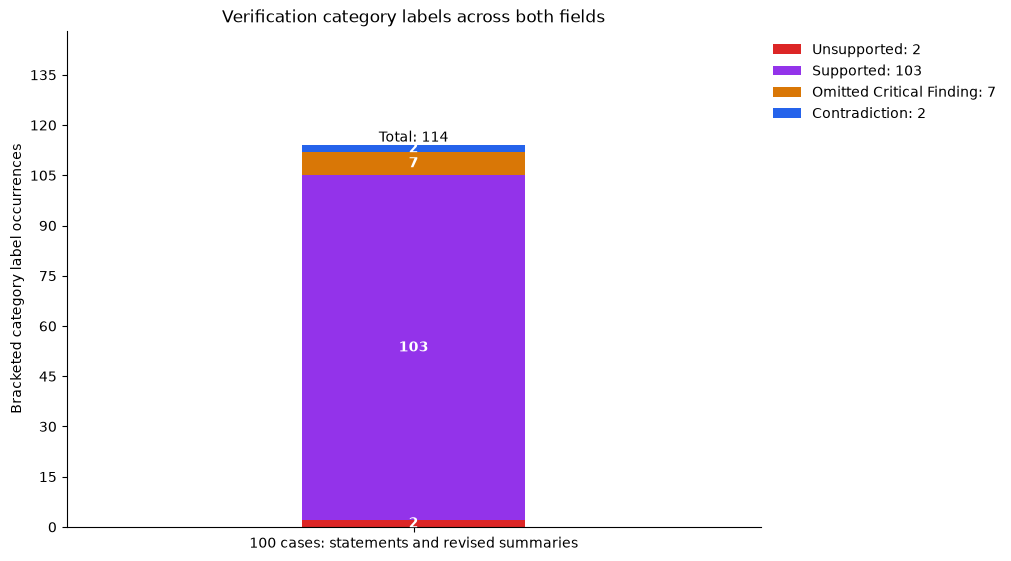

In [4]:
def step10_extract_verification_flags(cases):
    if not isinstance(cases, list) or len(cases) != 100:
        raise ValueError("Expected 100 combined Step 6 case results.")
    if any(not isinstance(case, dict) or not isinstance(case.get("id"), int) or not isinstance(case.get("statements"), str) or not case["statements"].strip() for case in cases):
        raise ValueError("Each Step 6 case must have an integer id and non-empty statements text.")
    if {case["id"] for case in cases} != set(range(1, 101)):
        raise ValueError("Expected unique Step 6 case IDs 1-100.")
    if any(not isinstance(case.get("summary"), dict) or not isinstance(case["summary"].get("revised"), str) for case in cases):
        raise ValueError("Each Step 6 case must contain summary.revised text.")
    categories = {
        "contradiction": "Contradiction",
        "contradictory": "Contradiction",
        "supported": "Supported",
        "unsupported": "Unsupported",
        "hallucinated": "Unsupported",
        "hallucination": "Unsupported",
        "omitted critical finding": "Omitted Critical Finding",
        "omission": "Omitted Critical Finding",
        "omitted": "Omitted Critical Finding",
    }
    flags = []
    for case in cases:
        for field, text in (("statements", case["statements"]), ("summary.revised", case["summary"]["revised"])):
            for line_number, line in enumerate(text.splitlines(), 1):
                for match in re.finditer(r"\[([^\]]+)\]", line):
                    label = " ".join(match.group(1).split()).casefold()
                    if label in categories:
                        flags.append({
                            "case_id": case["id"], "source_field": field,
                            "line_number": line_number, "character_offset": match.start(),
                            "verifier_label": label, "error_type": categories[label],
                        })
    return {
        "source_file": "step6_result.json", "cases_scanned": 100,
        "counting_rule": "Every bracketed label occurrence in statements and summary.revised; includes detached and repeated labels.",
        "flags": flags,
    }

def step10_plot_verification_flags(review):
    categories = ["Unsupported", "Supported", "Omitted Critical Finding", "Contradiction"]
    counts = {category: 0 for category in categories}
    for flag in review["flags"]:
        counts[flag["error_type"]] += 1
    fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
    bottom = 0
    for category, color in zip(categories, ["#dc2626", "#9333ea", "#d97706", "#2563eb"]):
        count = counts[category]
        ax.bar([0], [count], bottom=bottom, width=0.45, color=color, label=f"{category}: {count}")
        if count:
            ax.text(0, bottom + count / 2, str(count), ha="center", va="center", color="white", fontweight="bold")
        bottom += count
    ax.text(0, bottom + 0.08, f"Total: {bottom}", ha="center", va="bottom")
    ax.set_xticks([0], [f"{review['cases_scanned']} cases: statements and revised summaries"])
    ax.set_xlim(-0.7, 0.7)
    ax.set_ylim(0, max(1, bottom) * 1.3)
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_ylabel("Bracketed category label occurrences")
    ax.set_title("Verification category labels across both fields")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    return fig, ax

step10_verification_flags = step10_extract_verification_flags(load_intermediate("step6_result"))
save_intermediate("step10_verification_flags", step10_verification_flags)
step10_flags_figure, step10_flags_axes = step10_plot_verification_flags(step10_verification_flags)
plt.show()

### 10.4 Before-and-after category label counts

Read `intermediate_states/step10_verification_flags.json` and compare bracketed error-category labels in verification statements about the initial draft with labels present in revised summaries. Each occurrence is counted, including detached and repeated labels, following Step 10.3. These are label counts, not independently confirmed factual errors. A label in a revised summary does not prove an error remains; an absent label does not prove an error was fixed. The comparison therefore cannot measure factual improvement or a correction rate.

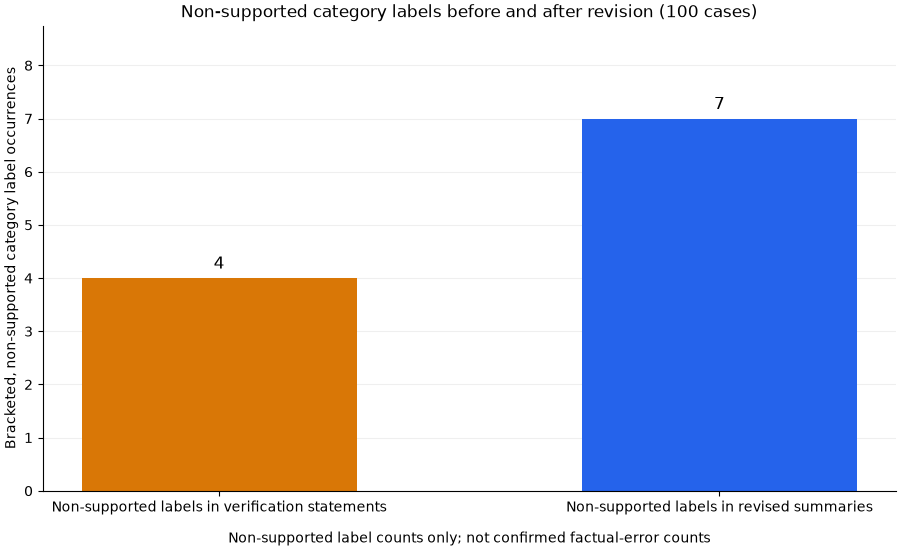

In [5]:
def load_intermediate(filename):
    with (Path("intermediate_states") / f"{filename}.json").open("r", encoding="utf-8") as file:
        return json.load(file)

def step10_plot_before_after_labels(review):
    fields = ["statements", "summary.revised"]
    counts = dict.fromkeys(fields, 0)
    categories = {"Unsupported", "Supported", "Omitted Critical Finding", "Contradiction"}
    for flag in review["flags"]:
        if flag["source_field"] not in counts or flag["error_type"] not in categories:
            raise ValueError("Expected Step 10.3 category labels from statements or summary.revised.")
        if flag["error_type"] == "Supported":
            continue
        counts[flag["source_field"]] += 1
    fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
    bars = ax.bar(
        ["Non-supported labels in verification statements", "Non-supported labels in revised summaries"],
        [counts[field] for field in fields], color=["#d97706", "#2563eb"], width=0.55,
    )
    ax.bar_label(bars, padding=4, fontsize=12)
    ax.set_ylim(0, max(1, *counts.values()) * 1.25)
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_ylabel("Bracketed, non-supported category label occurrences")
    ax.set_title(f"Non-supported category labels before and after revision ({review['cases_scanned']} cases)")
    ax.set_xlabel("Non-supported label counts only; not confirmed factual-error counts", labelpad=12)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    return fig, ax

matplotlib.use("Agg")
review = load_intermediate("step10_verification_flags")
step10_before_after_figure, step10_before_after_axes = step10_plot_before_after_labels(review)
source_field_counts = Counter(flag["source_field"] for flag in review["flags"])
bar_heights = [bar.get_height() for bar in step10_before_after_axes.patches]

buffer = BytesIO()
step10_before_after_figure.savefig(buffer, format="png")
image_png_base64 = base64.b64encode(buffer.getvalue()).decode("ascii")
plt.show = lambda *args, **kwargs: None
plt.show()
display({"image/png": image_png_base64, "text/plain": "Before-and-after non-supported label count"}, raw=True)

### 10.5 Statements checked versus verification runtime

**Preview:** `step10_use_dummy_data = True` displays 20 invented cases from `step10_verification_demo.json`, explicitly labelled as dummy data. These values are only for checking the chart layout, not experimental results. Set the switch to `False` after collecting real measurements in Step 9.

Step 9.1 now saves `intermediate_states/step10_verification_usage.json` automatically, using only the full-pipeline variant (20 cases on a complete run). Run 9.1 to collect timings, then run this cell. Partial checkpoints are explicitly marked in the chart. No models are run here. Manually supplied measurements must follow this JSON structure (replace nulls with measured values and include one record per case):

```json
{"measurement_type": "measured", "records": [{"case_id": 1, "statements_checked": null, "verification_seconds": null}]}
```

`case_id` must be a positive integer; `statements_checked` must be a non-negative integer counting the actual statements submitted for checking, not lines in the final log. `verification_seconds` must be a finite positive number: wall-clock time for both verification calls (statement splitting and checking), with accelerator synchronization where needed. Exclude other agents, model loading and JSON I/O. Use the same timing procedure for every case. The chart plots one point per case without fitting a trend. The measurement tag declares provenance; it does not independently verify it. Existing whole-document assigned runtimes cannot supply these measurements.

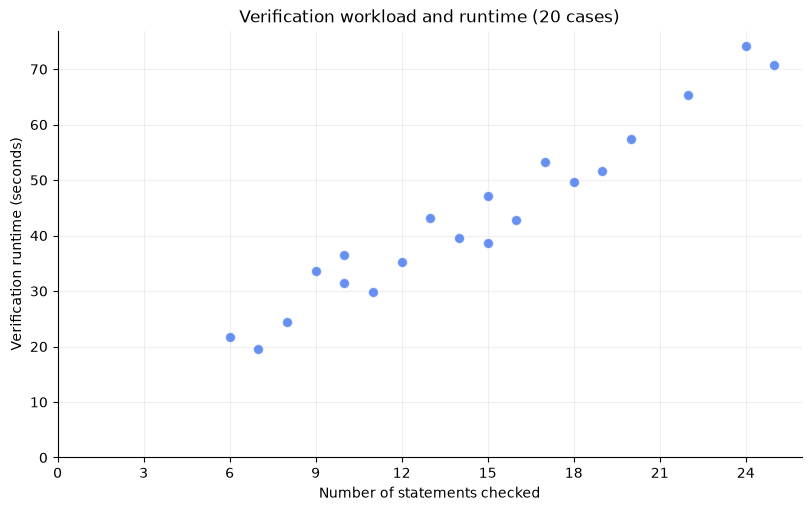

In [6]:
def step10_load_measurements(filename):
    path = Path("intermediate_states") / f"{filename}.json"
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path}. Supply measured data using the schema above this cell.")
    with path.open(encoding="utf-8") as file:
        return json.load(file)

def step10_measurement_records(payload, expected_type="measured"):
    if not isinstance(payload, dict) or payload.get("measurement_type") != expected_type:
        raise ValueError(f"Expected measurement_type={expected_type!r}; dummy data require explicit preview mode.")
    records = payload.get("records")
    if not isinstance(records, list) or not records:
        raise ValueError("Expected a non-empty records array of measured cases.")
    for record in records:
        if not isinstance(record, dict) or type(record.get("case_id")) is not int or record["case_id"] < 1:
            raise ValueError("Each record needs a positive integer case_id.")
    return records

def step10_validate_measurement(record, field, integer=False, positive=False):
    value = record.get(field)
    valid_type = type(value) is int if integer else type(value) in (int, float)
    if not valid_type or not math.isfinite(value) or value < 0 or (positive and value == 0):
        kind = "integer" if integer else "number"
        bound = "positive" if positive else "non-negative"
        raise ValueError(f"Case {record['case_id']}: {field} must be a finite {bound} {kind}.")
    return value

def step10_plot_verification_runtime(payload, *, demo=False):
    records = step10_measurement_records(payload, expected_type="dummy" if demo else "measured")
    if "complete" in payload and type(payload["complete"]) is not bool:
        raise ValueError("complete must be a boolean when provided.")
    ids = [record["case_id"] for record in records]
    if len(set(ids)) != len(ids):
        raise ValueError("Verification data must contain exactly one record per case_id.")
    counts = [step10_validate_measurement(row, "statements_checked", integer=True) for row in records]
    seconds = [step10_validate_measurement(row, "verification_seconds", positive=True) for row in records]
    fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
    ax.scatter(counts, seconds, color="#2563eb", alpha=0.7, edgecolors="white", s=55)
    ax.set_xlabel("Number of statements checked")
    ax.set_ylabel("Verification runtime (seconds)")
    status = "; partial checkpoint" if payload.get("complete") is False else ""
    ax.set_title(f"Verification workload and runtime ({len(records)} cases{status})")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_axisbelow(True)
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    return fig, ax

step10_use_dummy_data = True
step10_usage_file = "step10_verification_demo" if step10_use_dummy_data else "step10_verification_usage"
step10_verification_usage = step10_load_measurements(step10_usage_file)
step10_runtime_figure, step10_runtime_axes = step10_plot_verification_runtime(step10_verification_usage, demo=step10_use_dummy_data)
display(step10_runtime_figure)
plt.close(step10_runtime_figure)

Step 11: Synthesis, Literature Review & Final Reporting